In [1]:
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "tflmfi").exists():
            return p
    raise RuntimeError("Não encontrei a raiz do projeto (pyproject.toml + tflmfi).")

project_root = find_project_root(Path.cwd().resolve())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Notebook cwd:", Path.cwd())

Project root: C:\Downloads\framework_jose
Notebook cwd: c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811


In [2]:
from pathlib import Path
from IPython.display import display

from tflmfi import generate_physical_report, physical_heatmap_data

In [3]:
# Como seu notebook está dentro do run, o padrão é usar a pasta atual
run_dir = Path.cwd()

# Se quiser fixar manualmente, use algo como:
# run_dir = Path(r"c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811")

required = ["classified_results.csv", "selected_faults.csv", "tensor_map.csv"]
missing = [f for f in required if not (run_dir / f).exists()]

print("Run dir:", run_dir)
if missing:
    raise FileNotFoundError(f"Arquivos ausentes no run_dir: {missing}")
else:
    print("OK: arquivos necessários encontrados.")

Run dir: c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811
OK: arquivos necessários encontrados.


In [4]:
report = generate_physical_report(
    run_dir=run_dir,
    bin_size=128,      # ajuste: 64 para granularidade maior
    top_n_regions=10
)

print(report.summary())

saved_files = report.save(run_dir)
print("\nArquivos gerados:")
for p in saved_files:
    print("-", p)

  Model-Physical Analysis Report

  Total enriched fault results: 179,400

  Most critical tensor: sequential_1_1/dense_3_1/BiasAdd (rate=0.335)
  Most critical operator: CONV_2D (rate=0.046)

  Semantic vs Physical verdict: physical
    Semantic  Gini=0.6030  Entropy=2.3286
    Physical  Gini=0.8140  Entropy=5.1156
    Criticality is more concentrated by physical address range than by tensor/operator.

  Hottest physical region: [0x1540, 0x1580) rate=0.408 (500.0 faults)
  Most vulnerable bit position: bit 7 (rate=0.038)


Arquivos gerados:
- c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811\analysis_physical_bins.csv
- c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811\analysis_criticality_by_tensor.csv
- c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811\analysis_criticality_by_operator.csv
- c:\Downloads\framework_jose\runs\Memoria_transient\mem

In [5]:
print("Top 10 tensores mais críticos:")
display(report.by_tensor.head(10))

print("Top 10 operadores mais críticos:")
display(report.by_operator.head(10))

print("Top 10 regiões físicas mais críticas:")
display(report.critical_regions.head(10))

print("Vulnerabilidade por bit:")
display(report.bit_vulnerability)

Top 10 tensores mais críticos:


,tensor_index,tensor_name,total,critical,crash,degraded,critical_rate,degraded_rate,phys_start,tensor_size
0,2.0,sequential_1_1/dense_3_1/BiasAdd,3500,1172,0,1217,0.334857,0.347714,26804,40
1,8.0,sequential_1_1/conv2d_4_1/Relu;sequential_1_1/...,1000,271,0,320,0.271000,0.320000,5420,128
2,4.0,sequential_1_1/dense_2_1/Relu;sequential_1_1/d...,2100,361,0,448,0.171905,0.213333,26332,128
3,10.0,sequential_1_1/conv2d_3_1/Relu;sequential_1_1/...,8800,1193,0,1917,0.135568,0.217841,724,64
4,6.0,sequential_1_1/conv2d_5_1/Relu;sequential_1_1/...,100,9,0,33,0.090000,0.330000,24004,256
5,11.0,sequential_1_1/conv2d_3_1/convolution,22500,258,0,1154,0.011467,0.051289,568,144
6,9.0,sequential_1_1/conv2d_4_1/convolution,37100,135,0,896,0.003639,0.024151,800,4608
7,3.0,sequential_1_1/dense_3_1/MatMul,30500,110,0,393,0.003607,0.012885,26472,320
8,5.0,sequential_1_1/dense_2_1/MatMul,35500,85,0,509,0.002394,0.014338,24272,2048
9,7.0,sequential_1_1/conv2d_5_1/convolution,38300,82,0,381,0.002141,0.009948,5560,18432


Top 10 operadores mais críticos:


,op_index,op_name,total,critical,crash,critical_rate,degraded_rate
0,0,CONV_2D,31300,1451,0,0.046358,0.098115
1,7,FULLY_CONNECTED,34000,1282,0,0.037706,0.047353
2,6,FULLY_CONNECTED,37600,446,0,0.011862,0.025452
3,2,CONV_2D,38100,406,0,0.010656,0.031916
4,4,CONV_2D,38400,91,0,0.002370,0.010781


Top 10 regiões físicas mais críticas:


,bin_start,bin_end,total,masked,acceptable,warning,critical,crash,critical_rate,degraded_rate
0,5440,5504,500,227,44,25,204,0,0.408000,0.458000
1,26816,26880,2900,1835,170,45,837,0,0.288621,0.304138
2,5504,5568,300,212,12,12,64,0,0.213333,0.253333
3,26368,26432,700,529,47,22,98,0,0.140000,0.171429
4,704,768,7000,4119,1545,502,813,0,0.116143,0.187857
5,768,832,3400,2025,725,248,383,0,0.112647,0.185588
6,26304,26368,1300,919,161,69,142,0,0.109231,0.162308
7,24064,24128,100,36,31,24,9,0,0.090000,0.330000
8,26752,26816,4300,3825,113,16,340,0,0.079070,0.082791
9,26432,26496,3200,2814,206,41,129,0,0.040313,0.053125


Vulnerabilidade por bit:


,bit_index,total,critical,crash,critical_rate,degraded_rate
0,0,23600,298,0,0.012627,0.019068
1,1,21500,336,0,0.015628,0.024930
2,2,24900,257,0,0.010321,0.021446
3,3,19900,390,0,0.019598,0.031960
4,4,23100,391,0,0.016926,0.034978
5,5,22700,714,0,0.031454,0.054934
6,6,21900,469,0,0.021416,0.055251
7,7,21800,821,0,0.037661,0.084725


In [7]:
pip install matplotlib

  Using cached matplotlib-3.10.8-cp312-cp312-win_amd64.whl.metadata (52 kB)
  Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.62.1-cp312-cp312-win_amd64.whl.metadata (119 kB)
  Using cached kiwisolver-1.5.0-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.10.8-cp312-cp312-win_amd64.whl (8.1 MB)
Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl (226 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.62.1-cp312-cp312-win_amd64.whl (2.3 MB)
Using cached kiwisolver-1.5.0-cp312-cp312-win_amd64.whl (73 kB)
   ---------------------------------------- 0.0/7.1 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/7.1 MB 20.9 MB/s eta 0:00:01
   ------------ --------------------------- 2.2/7.1 MB 23.0 MB/s eta 0:00:01
   -------------------- --------


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: c:\Downloads\framework_jose\.venv\Scripts\python.exe -m pip install --upgrade pip


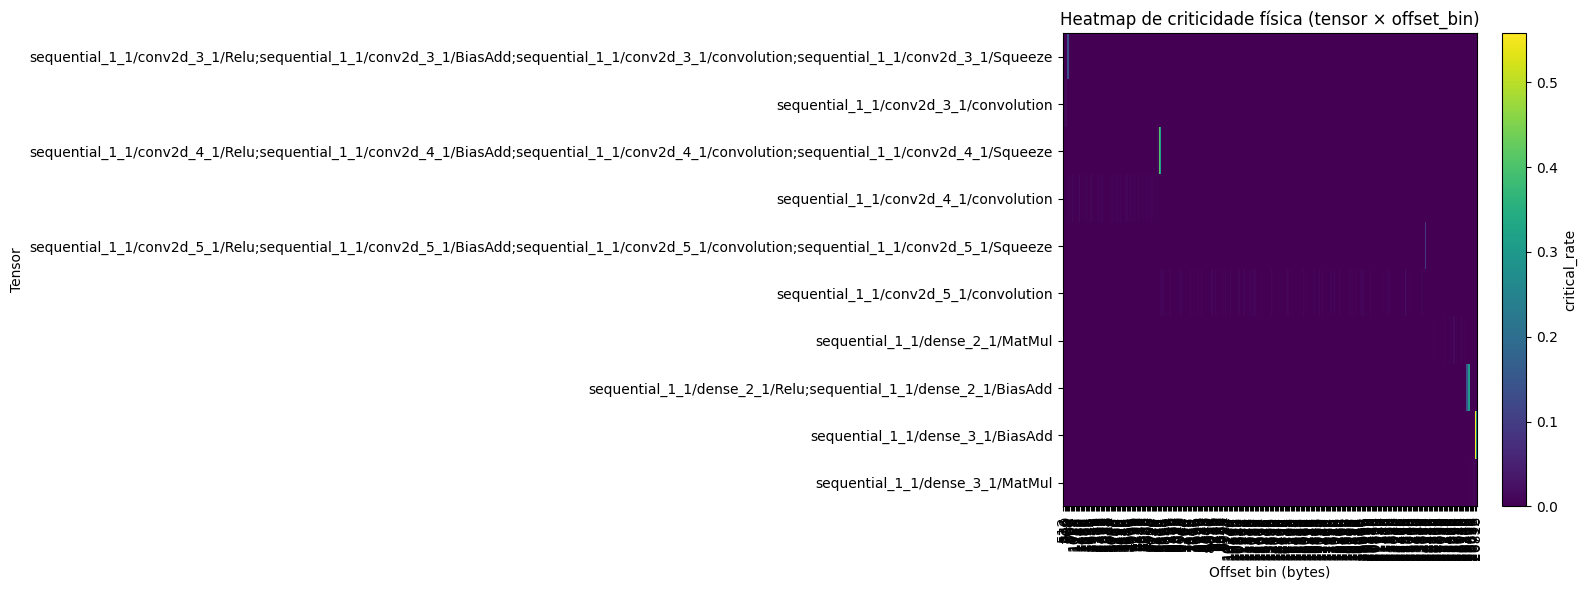

In [8]:
import matplotlib.pyplot as plt

# tenta seaborn (melhor visual), mas funciona sem ele
try:
    import seaborn as sns
    use_sns = True
except Exception:
    use_sns = False

heat = physical_heatmap_data(
    report.enriched,
    bin_size=64,
    metric="critical_rate",   # pode trocar para "degraded_rate"
)

if heat.empty:
    print("Heatmap vazio (sem dados suficientes para tensor_name/global_byte_offset).")
else:
    plt.figure(figsize=(16, max(6, 0.35 * len(heat.index))))
    if use_sns:
        sns.heatmap(heat, cmap="Reds", cbar_kws={"label": "critical_rate"})
    else:
        plt.imshow(heat.values, aspect="auto", interpolation="nearest")
        plt.colorbar(label="critical_rate")
        plt.yticks(range(len(heat.index)), heat.index)
        plt.xticks(range(len(heat.columns)), heat.columns, rotation=90)

    plt.title("Heatmap de criticidade física (tensor × offset_bin)")
    plt.xlabel("Offset bin (bytes)")
    plt.ylabel("Tensor")
    plt.tight_layout()
    plt.show()

In [9]:
out_dir = run_dir / "notebook_exports"
out_dir.mkdir(exist_ok=True)

report.by_tensor.head(20).to_csv(out_dir / "top20_tensors.csv", index=False)
report.by_operator.head(20).to_csv(out_dir / "top20_operators.csv", index=False)
report.critical_regions.to_csv(out_dir / "critical_regions.csv", index=False)

print("Exports em:", out_dir)

Exports em: c:\Downloads\framework_jose\runs\Memoria_transient\memoryfi_image_classification_20260417_092811\notebook_exports
